# Chapter 36 - Validation and Calibration

Chapter 35 ended with Model 2: Search repaired, and Meta and YouTube known well as a pair but not as a split.
This notebook follows Chapter 36.
It validates Model 2 on held-out weeks, runs time-slice cross-validation, adds the Meta geo holdout as one extra likelihood term, and shows why that experiment narrows Meta's annual interval only a little.
It ends with the final channel estimates, the decomposition of revenue into baseline, controls and media, and a check against the truth the generator built in.
Every number Chapter 36 prints is computed here; `mmm_book.case_results.chapter36` computes the same numbers for the book's tests and figures.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mmm_book import RANDOM_SEED
from mmm_book.case_model import (
    Y_SCALE,
    decompose,
    fit_case_model,
    holdout_lift_draws,
    posterior_mu,
    prepare_case_data,
    roas_table,
)
from mmm_book.experiment import (
    EXPERIMENT_LIFT_GBP,
    EXPERIMENT_ROAS,
    EXPERIMENT_SE_GBP,
    EXPERIMENT_WITHHELD_SPEND_GBP,
    ledger_holdout_design,
    ledger_push_design,
    placebo_se,
)
from mmm_book.plotting import mmm_style
from mmm_book.sedge import CHANNELS, GROUND_TRUTH, LAUNCHES, correct_distribution, generate_sedge

mmm_style()
pd.set_option("display.width", 120)
fixed = correct_distribution(generate_sedge(seed=RANDOM_SEED))
data = prepare_case_data(fixed, "model2")

## Held-out weeks that look fine until the launch

Model 2 is fitted to the first 130 weeks and asked to predict the last 26, which it has never seen.
Everything computed from the data before fitting comes from the 130 training weeks alone: the scaling of the controls and the trend, each region's reference media activity (the base of the half-saturation point), its average revenue and the spend that defines ROAS.
`prepare_case_data(..., train_weeks=130)` does that, so nothing about the test weeks leaks into training (Chapter 21).

In [2]:
TRAIN = 130
data_130 = prepare_case_data(fixed, "model2", train_weeks=TRAIN)
idata_130 = fit_case_model(fixed, "model2", train_weeks=TRAIN)
print(f"divergent transitions: {int(idata_130.sample_stats['diverging'].sum())}")

mu = posterior_mu(idata_130, data_130) * Y_SCALE
actual = data_130.y.sum(axis=0) * Y_SCALE
predicted = mu.sum(axis=0)
test = data_130.weeks >= TRAIN
launch_start = LAUNCHES[2][0]
in_launch = (data_130.weeks >= launch_start) & (data_130.weeks < launch_start + 6)

wmape = np.abs(actual - predicted)[test].sum() / actual[test].sum()
print(f"test weeks {TRAIN} to {data_130.weeks[-1]}: national weighted MAPE {wmape:.1%}")
print(
    f"  outside the week-{launch_start} launch: mean error "
    f"{(actual - predicted)[test & ~in_launch].mean():+,.0f} a week"
)
print(
    f"  during the launch:            mean error {(actual - predicted)[in_launch].mean():+,.0f} "
    f"a week"
)

divergent transitions: 0


test weeks 130 to 155: national weighted MAPE 4.7%
  outside the week-141 launch: mean error +13,263 a week
  during the launch:            mean error +117,328 a week


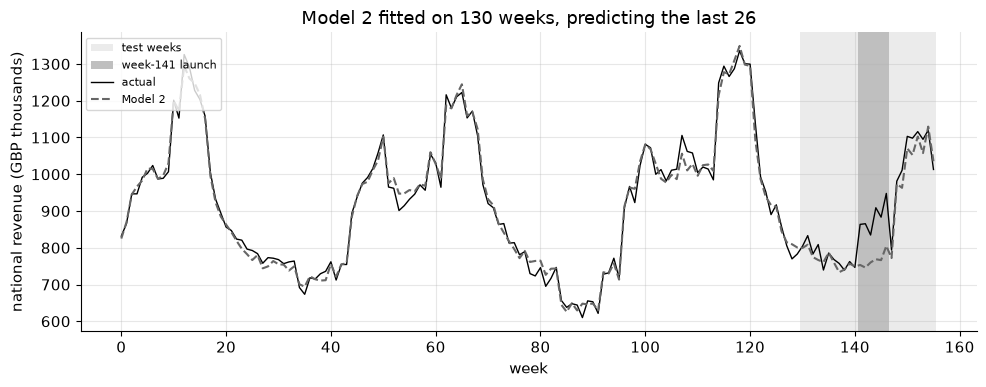

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(TRAIN - 0.5, data.weeks[-1] + 0.5, color="0.92", lw=0, label="test weeks")
ax.axvspan(
    launch_start - 0.5, launch_start + 5.5, color="0.75", lw=0, label=f"week-{launch_start} launch"
)
ax.plot(data.weeks, actual / 1e3, color="k", lw=1, label="actual")
ax.plot(data.weeks, predicted / 1e3, color="0.4", lw=1.5, ls="--", label="Model 2")
ax.set_xlabel("week")
ax.set_ylabel("national revenue (GBP thousands)")
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Model 2 fitted on 130 weeks, predicting the last 26")
fig.tight_layout()

Point accuracy is good across most of the test weeks, and the model systematically underpredicts the launch.
Each launch has its own uplift, with a wide prior centred on a 5 per cent lift.
The two launches in the training window are learned from the data; the third never appears in training, so its forecast is the prior's centre, far below the 25 per cent lift the generator gave it.

In [4]:
launch = az.summary(idata_130, var_names=["launch_effect"], kind="stats")
print(launch.round(3))
print(f"\ntrue uplifts: {[size for _, size in LAUNCHES]}")

                          mean      sd eti89_lb eti89_ub
launch_effect[launch_1]  0.039  0.0093    0.024    0.054
launch_effect[launch_2]  0.047  0.0094    0.032    0.062
launch_effect[launch_3]   0.05     0.1    -0.11     0.21

true uplifts: [0.08, 0.08, 0.25]


The team considers a more flexible launch effect and rejects it, because only three events exist.
It keeps the wide prior on each launch, so a launch the model has not seen carries wide uncertainty, and reports the miss as a limitation.

## Time-slice cross-validation

The same model is refitted on growing windows: the first 104 weeks, the first 130, and all 156, each prepared from its own training weeks.
The question is which channels are stable.

In [5]:
idata_104 = fit_case_model(fixed, "model2", train_weeks=104)
data_104 = prepare_case_data(fixed, "model2", train_weeks=104)
idata_full = fit_case_model(fixed, "model2")
folds = pd.DataFrame(
    {
        "104 weeks": roas_table(idata_104, data_104)["roas_mean"],
        "130 weeks": roas_table(idata_130, data_130)["roas_mean"],
        "156 weeks": roas_table(idata_full, data)["roas_mean"],
    }
)
folds["range"] = folds.max(axis=1) - folds.min(axis=1)
folds.round(2)

,104 weeks,130 weeks,156 weeks,range
channel,,,,
tv,2.58,2.63,2.57,0.06
search,2.50,2.27,2.23,0.27
meta,1.41,1.62,1.52,0.21
youtube,1.81,1.61,2.34,0.73
ooh,1.82,1.78,1.65,0.17


Television barely moves across the folds, and YouTube moves most: when two channels share a budget, each new slice of data can move credit between them.
Search, Meta and OOH sit in between.

## Model 2 before calibration

The full 156-week fit, with each channel's annual contribution and a 90 per cent credible interval.
This is the table Chapter 36 prints.

In [6]:
before = roas_table(idata_full, data)
print(before.round(2))
print(f"\ntotal annual contribution: {before['annual_contribution_m'].sum():.2f}m")

         roas_mean  roas_lo  roas_hi  annual_contribution_m
channel                                                    
tv            2.57     2.41     2.74                   3.60
search        2.23     1.73     2.77                   3.12
meta          1.52     0.90     2.29                   2.28
youtube       2.34     1.36     3.45                   1.87
ooh           1.65     1.14     2.28                   1.48

total annual contribution: 12.35m


The rows are not equally certain.
Television's interval is the narrowest, Meta's and YouTube's the widest.

## The calibration experiment

Sixteen regions are paired on pre-period Meta spend, and in one region of each pair Meta is paused for six weeks while the other continues as usual, with YouTube held stable.
`mmm_book.experiment` rebuilds the design from the panel.

In [7]:
design = ledger_holdout_design()
print(f"treatment regions: {design['treatment_regions']}")
print(
    f"business-as-usual Meta spend: {design['weekly_bau_spend']:,.0f} a week; "
    f"withheld over six weeks: {design['withheld_spend']:,.0f}"
)
print(f"placebo standard error of the estimator: {placebo_se()['se']:,.0f}")
print()
print(
    f"observed lift {EXPERIMENT_LIFT_GBP:,.0f} (se {EXPERIMENT_SE_GBP:,.0f}) on "
    f"{EXPERIMENT_WITHHELD_SPEND_GBP:,.0f} withheld"
)
roas_lo = (EXPERIMENT_LIFT_GBP - 1.96 * EXPERIMENT_SE_GBP) / EXPERIMENT_WITHHELD_SPEND_GBP
roas_hi = (EXPERIMENT_LIFT_GBP + 1.96 * EXPERIMENT_SE_GBP) / EXPERIMENT_WITHHELD_SPEND_GBP
print(f"experiment ROAS {EXPERIMENT_ROAS:.2f}, rough 95% interval {roas_lo:.1f} to {roas_hi:.1f}")
print(f"lift / se = {EXPERIMENT_LIFT_GBP / EXPERIMENT_SE_GBP:.1f} standard errors from zero")

treatment regions: [0, 1, 7, 9, 11, 12, 13, 15]
business-as-usual Meta spend: 12,870 a week; withheld over six weeks: 77,223
placebo standard error of the estimator: 45,013

observed lift 138,000 (se 45,000) on 77,000 withheld
experiment ROAS 1.79, rough 95% interval 0.6 to 2.9
lift / se = 3.1 standard errors from zero


The design decides what the number means.
A holdout measures the return on the spend that was switched off, an average-type return for that slice of spend.
A push in the same regions would have measured the return on extra pounds, which on a concave curve cannot exceed the marginal return at the starting point.
The generator's own true curve shows the difference.

In [8]:
push = ledger_push_design()
print(f"holdout on the true curve: ROAS {design['expected_roas']:.2f} on the withheld spend")
print(
    f"push on the true curve:    ROAS {push['roas']:.2f} on {push['extra_spend']:,.0f} of extra "
    f"spend"
)

holdout on the true curve: ROAS 1.55 on the withheld spend
push on the true curve:    ROAS 0.47 on 180,777 of extra spend


## What the model predicted for the test

Before the experiment enters the model, the uncalibrated Model 2 can be asked what it expects the test to find: switch Meta off in the treatment regions for the six test weeks, push that through each posterior draw's own adstock and saturation, and sum the lost revenue over the eight-week window.
`holdout_lift_draws` does exactly the calculation the calibration term uses.

In [9]:
lift_before = holdout_lift_draws(idata_full, data)
meta_before = idata_full.posterior["roas_meta"].to_numpy().ravel()
test_roas_before = lift_before / EXPERIMENT_WITHHELD_SPEND_GBP
lo, hi = np.quantile(lift_before, [0.05, 0.95])
print(
    f"predicted lift: {lift_before.mean():,.0f} (90% interval {lo:,.0f} to {hi:,.0f}), "
    f"standard deviation {lift_before.std():,.0f}"
)
print(f"experiment's own standard error: {EXPERIMENT_SE_GBP:,.0f}")
print(
    f"predicted test ROAS {test_roas_before.mean():.2f}; annual Meta ROAS {meta_before.mean():.2f}"
)
ratio = meta_before / test_roas_before
print(
    f"annual ROAS / test ROAS: {ratio.mean():.2f} "
    f"(90% interval {np.quantile(ratio, 0.05):.2f} to {np.quantile(ratio, 0.95):.2f})"
)

predicted lift: 97,429 (90% interval 58,749 to 143,336), standard deviation 25,631
experiment's own standard error: 45,000
predicted test ROAS 1.27; annual Meta ROAS 1.52
annual ROAS / test ROAS: 1.21 (90% interval 1.03 to 1.51)


Two things follow, and they explain the rest of the notebook.
First, the model already knew the test's lift to within a standard deviation of about £26,000, because three years of sales in those eight regions carry a lot of information about what Meta earns there; the experiment's standard error, £45,000, is larger.
Second, the annual return is about 1.2 times the test return, and that ratio is uncertain (it depends on the curve's shape), which the six-week test cannot inform.

## Calibrating Model 2

The experiment enters as one more observation: the observed £138,000, with standard deviation £45,000, is treated as a noisy measurement of the lift the model's own Meta curve implies for the same regions and weeks.
It enters only there; the Meta prior was set before the test and does not use it.

In [10]:
idata_cal = fit_case_model(fixed, "model2", calibrate=True)
print(f"divergent transitions: {int(idata_cal.sample_stats['diverging'].sum())}")
after = roas_table(idata_cal, data)
lift_after = holdout_lift_draws(idata_cal, data)
meta_after = idata_cal.posterior["roas_meta"].to_numpy().ravel()
print(
    f"lift the calibrated model implies for the test: {lift_after.mean():,.0f} "
    f"(standard deviation {lift_after.std():,.0f}; observed {EXPERIMENT_LIFT_GBP:,.0f})"
)
combined = 1 / np.sqrt(1 / lift_before.std() ** 2 + 1 / EXPERIMENT_SE_GBP**2)
print(
    f"two independent readings of the lift would combine to a standard deviation of {combined:,.0f}"
)

shift = pd.DataFrame(
    {
        "before": before["roas_mean"],
        "before 5%": before["roas_lo"],
        "before 95%": before["roas_hi"],
        "after": after["roas_mean"],
        "after 5%": after["roas_lo"],
        "after 95%": after["roas_hi"],
    }
)
print(shift.loc[["meta", "youtube"]].round(2))
width = (after.loc["meta", "roas_hi"] - after.loc["meta", "roas_lo"]) / (
    before.loc["meta", "roas_hi"] - before.loc["meta", "roas_lo"]
)
print(f"\nMeta's 90% interval narrows by {1 - width:.0%}")

divergent transitions: 0


lift the calibrated model implies for the test: 106,617 (standard deviation 23,412; observed 138,000)
two independent readings of the lift would combine to a standard deviation of 22,272
         before  before 5%  before 95%  after  after 5%  after 95%
channel                                                           
meta       1.52       0.90        2.29   1.65      1.05       2.36
youtube    2.34       1.36        3.45   2.20      1.24       3.27

Meta's 90% interval narrows by 6%


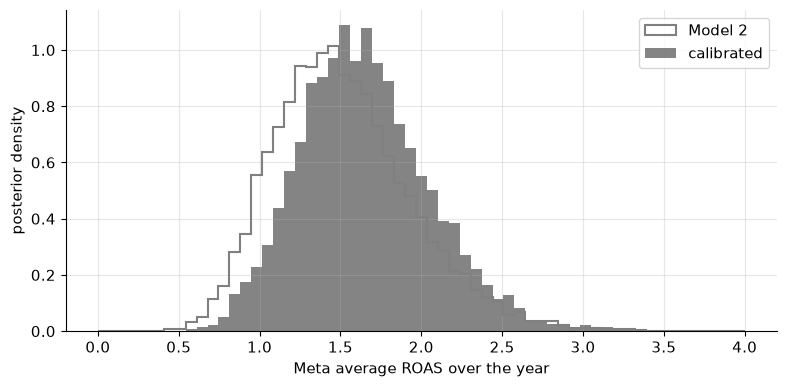

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 4, 60)
ax.hist(meta_before, bins=bins, density=True, histtype="step", color="0.5", lw=1.5, label="Model 2")
ax.hist(
    meta_after,
    bins=bins,
    density=True,
    histtype="stepfilled",
    color="0.2",
    alpha=0.6,
    label="calibrated",
)
ax.set_xlabel("Meta average ROAS over the year")
ax.set_ylabel("posterior density")
ax.legend()
fig.tight_layout()

Calibration moves Meta's centre towards the experiment, from about 1.52 to about 1.65, because the observed lift is above what the model predicted, and it lifts the bottom of the interval.
The interval narrows by only about 6 per cent.
The experiment was the weaker of the two sources on the one quantity it measured, so it moves the lift's uncertainty only from about £26,000 to about £23,000, and turning a six-week test return into an annual return adds shape uncertainty the test does not touch.
To match the precision the sales history already had, the test would have needed roughly three times as many region-weeks; to narrow the annual interval sharply, tests at more than one spend level.
YouTube eases down, because a Meta that is clearly not worthless leaves less of their shared effect for YouTube.

## The final channel estimates

The calibrated model's estimates are the table Chapter 36 prints and Part IX plans on.

In [12]:
final = after[["roas_mean", "roas_lo", "roas_hi", "annual_contribution_m"]].copy()
print(final.round(2))
total = final["annual_contribution_m"].sum()
print(f"\ntotal incremental revenue: {total:.2f}m, portfolio ROAS {total / 6.0:.2f}")
profit = 0.5 * final["annual_contribution_m"] - pd.Series(
    {ch: data.annual_spend(ch) / 1e6 for ch in CHANNELS}
)
print(f"short-run profit at a 50% margin: {profit.round(2).to_dict()}, total {profit.sum():.2f}m")

         roas_mean  roas_lo  roas_hi  annual_contribution_m
channel                                                    
tv            2.57     2.40     2.74                   3.60
search        2.22     1.71     2.77                   3.11
meta          1.65     1.05     2.36                   2.48
youtube       2.20     1.24     3.27                   1.76
ooh           1.65     1.16     2.29                   1.49

total incremental revenue: 12.43m, portfolio ROAS 2.07
short-run profit at a 50% margin: {'tv': 0.4, 'search': 0.15, 'meta': -0.26, 'youtube': 0.08, 'ooh': -0.16}, total 0.21m


## Decomposing revenue

The case model's baseline and controls are multiplicative, so a control's contribution in pounds is the baseline times the control's multiplier minus one, measured from a stated reference level.
`decompose` uses no promotion and the £95 list price as the reference, with every other control at its average, and the baseline is each region's level with trend, seasonality and the launches.

In [13]:
dec = decompose(idata_cal, data)
rows = {k: v / 1e6 for k, v in dec.items()}
table = pd.DataFrame(
    {
        "mean": {k: v.mean() for k, v in rows.items()},
        "5%": {k: np.quantile(v, 0.05) for k, v in rows.items()},
        "95%": {k: np.quantile(v, 0.95) for k, v in rows.items()},
    }
)
print(table.round(2))

            mean     5%    95%
baseline   33.75  32.27  35.00
controls    1.81   1.76   1.87
promotion   0.92   0.85   0.99
price       0.73   0.67   0.79
media      12.39  11.15  13.84
fitted     47.95  47.86  48.05
actual     47.95  47.95  47.95
residual   -0.00  -0.10   0.09


About £33.7 million of baseline, £12.4 million of media, £1.8 million from the controls (mostly promotions, about £0.9 million, and selling below the list price, about £0.7 million) and a residual close to zero, adding to the £47.9 million of a year's revenue.

## Checking against the truth

Because the data are synthetic, the true returns are known.
The chapter keeps them in a box; here they sit beside the fit.

In [14]:
check = final[["roas_mean", "roas_lo", "roas_hi"]].copy()
check["truth"] = pd.Series(GROUND_TRUTH)
check["inside"] = (check["roas_lo"] <= check["truth"]) & (check["truth"] <= check["roas_hi"])
print(check.round(3))
truth_total = sum(GROUND_TRUTH[ch] * data.annual_spend(ch) / 1e6 for ch in CHANNELS)
print(f"\nmodel total {total:.2f}m against true {truth_total:.2f}m")

         roas_mean  roas_lo  roas_hi  truth  inside
channel                                            
tv           2.568    2.404    2.737   2.40   False
search       2.218    1.707    2.772   2.70    True
meta         1.652    1.045    2.357   1.75    True
youtube      2.200    1.242    3.272   2.00    True
ooh          1.652    1.159    2.285   1.50    True

model total 12.43m against true 12.71m


Four of five intervals contain the truth; Television's lower end sits a hair above the true 2.4.
Search is the channel the model recovers least well, inside its interval but well below the truth.

## Takeaway

Validation and calibration earn a model trust; a clean trace plot does not.
The test weeks showed where Model 2 is weak (a launch larger than anything in its history), and the team reported that and declined to over-fit three events.
Cross-validation showed which channels are stable.
The Meta holdout added independent evidence that agrees with the model, and it showed how much a test needs to be worth before it can move an estimate the sales history already pins down.